# Pipeline OSIPTEL v2 — Sustracción de equipos móviles

**Grupo 11 · Big Data y Analítica de Datos · UPAO 2026-20**

Ejecuta las celdas en orden. Cada etapa deja evidencia en `docs/evidencia/` y muestra su resultado aquí: **guarda el notebook con las salidas** y súbelo al repositorio (es la evidencia de ejecución del Anexo).

Fuentes: F1 equipos sustraídos/perdidos/recuperados (XLSX), F2 reclamos presentados (XLSX), F3 cobertura móvil (CSV). Ver `README.md` §2 para descargarlas.

## 0. Entorno

In [1]:
import os, sys, json, time, shutil
from pathlib import Path
# JAVA_HOME: se deduce del java que está en el PATH (sirve para Java 11, 17 o 21)
if 'JAVA_HOME' not in os.environ and shutil.which('java'):
    os.environ['JAVA_HOME'] = str(Path(os.path.realpath(shutil.which('java'))).parents[1])
# SPARK_HOME: solo si existe la instalación manual; si no, se usa el pyspark instalado con pip
if 'SPARK_HOME' not in os.environ and Path('/opt/spark-3.5.1-bin-hadoop3').exists():
    os.environ['SPARK_HOME'] = '/opt/spark-3.5.1-bin-hadoop3'
print('JAVA_HOME =', os.environ.get('JAVA_HOME'), '| SPARK_HOME =', os.environ.get('SPARK_HOME', '(pyspark de pip)'))
os.environ['PYSPARK_PYTHON'] = sys.executable
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
import config, ingesta, transform, gold, modelo, figuras
from pipeline import spark_session
spark = spark_session('OSIPTEL_notebook')
print('Spark', spark.version, '| master', spark.sparkContext.master, '| lake', config.LAKE)

26/11/06 21:49:39 WARN Utils: Your hostname, Debian resolves to a loopback address: 127.0.1.1; using 10.0.2.15 instead (on interface enp0s3)
26/11/06 21:49:39 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/06 21:49:42 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.1 | master local[*] | lake file:///home/olazabal/big-data-sustraccion-equipos-moviles-peru/data/lake


## 1. Ingesta RAW → STAGING (manifiesto de procedencia con SHA-256)

In [2]:
manifiesto = ingesta.ingestar()
import pandas as pd
pd.DataFrame(manifiesto['fuentes']).T

[INGESTA] 276,008 filas en 30.63 s


,archivo,formato,bytes,sha256,filas
robos,9.1. EQUIPOS SUSTRAIDOS PERDIDOS O RECUPERADOS...,XLSX,69497,db9f686cb7fd6e656ab6c74345fe6d70450890a8d71181...,1698
reclamos,10.1 RECLAMOS PRESENTADOS.xlsx,XLSX,7155242,4b27d6ff5cc6758cc08a5461b9b5e5f0a8fe5085797d69...,222944
cobertura,Cobertura móvil por empresa operadora.csv,CSV ;,7590550,0e2c5336ca94ad9ab2e94dd1ae2d7a7a487ffda47c54e9...,51366


## 2. SILVER: limpieza y reglas de calidad (aceptados / rechazados)

In [3]:
calidad = {}
s_rob, q_rob, calidad['robos'] = transform.silver_robos(transform.leer_robos(spark))
s_rec, q_rec, calidad['reclamos'] = transform.silver_reclamos(transform.leer_reclamos(spark))
s_cob, q_cob, calidad['cobertura'] = transform.silver_cobertura(transform.leer_cobertura(spark))
pd.DataFrame(calidad).T

[SILVER] robos: leídos=1,698 aceptados=1,698 rechazados=0


[SILVER] reclamos: leídos=222,944 aceptados=222,944 rechazados=0


[Stage 39:>                                                         (0 + 1) / 1]

[SILVER] cobertura: leídos=51,366 aceptados=51,366 rechazados=0


,fuente,leidos,aceptados,rechazados,pct_validos,motivos,sin_departamento_marcados,departamentos_crudos,departamentos_normalizados
robos,robos,1698,1698,0,100.0,{},NaN,NaN,NaN
reclamos,reclamos,222944,222944,0,100.0,NaN,17475,NaN,NaN
cobertura,cobertura,51366,51366,0,100.0,NaN,NaN,45,24


In [4]:
s_rob.printSchema(); s_rec.printSchema(); s_cob.printSchema()

root
 |-- fecha_mes: date (nullable = true)
 |-- operadora: string (nullable = false)
 |-- estado: string (nullable = true)
 |-- cantidad: long (nullable = true)
 |-- razones_sociales: array (nullable = false)
 |    |-- element: string (containsNull = false)

root
 |-- fecha_mes: date (nullable = true)
 |-- anio: integer (nullable = true)
 |-- operadora: string (nullable = false)
 |-- razon_social: string (nullable = true)
 |-- departamento: string (nullable = true)
 |-- servicio: string (nullable = true)
 |-- materia: string (nullable = true)
 |-- forma: string (nullable = true)
 |-- reclamos: long (nullable = true)
 |-- es_movil: boolean (nullable = true)

root
 |-- periodo_fecha: date (nullable = true)
 |-- operadora: string (nullable = false)
 |-- departamento: string (nullable = true)
 |-- ubigeo_distrito: string (nullable = true)
 |-- ubigeo_ccpp: string (nullable = true)
 |-- tiene_2g: integer (nullable = true)
 |-- tiene_3g: integer (nullable = true)
 |-- tiene_4g: integer (nul

In [5]:
gold.escribir(s_rob, 'silver', 'robos', ['operadora'])
gold.escribir(s_rec, 'silver', 'reclamos', ['anio'])
gold.escribir(s_cob, 'silver', 'cobertura', ['operadora'])
for n, q in [('robos', q_rob), ('reclamos', q_rec), ('cobertura', q_cob)]:
    gold.escribir(q, 'quarantine', n)

[ESCRITURA] silver/robos


[ESCRITURA] silver/reclamos


[ESCRITURA] silver/cobertura
[ESCRITURA] quarantine/robos


[ESCRITURA] quarantine/reclamos


26/11/06 21:51:18 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

[ESCRITURA] quarantine/cobertura


## 3. GOLD: integración (2 JOIN) y modelo dimensional

In [6]:
rob = spark.read.parquet(config.ruta('silver','robos'))
rec = spark.read.parquet(config.ruta('silver','reclamos')).cache()
cob = spark.read.parquet(config.ruta('silver','cobertura'))
j1 = gold.gold_operadora_mes(rob, rec)
j2 = gold.gold_depto_operadora(cob, rec)
j1.explain()   # plan físico: evidencia del JOIN
gold.escribir(j1, 'gold', 'gold_operadora_mes', ['anio'])
gold.escribir(j2, 'gold', 'gold_depto_operadora_202303')
for n, df in zip(['dim_tiempo','dim_operadora','dim_departamento'], gold.dimensiones(spark, rob, rec, cob)):
    gold.escribir(df, 'gold', n)

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [fecha_mes#1367, operadora#1368, sustraidos#1321L, recuperados#1327L, perdidos#1333L, reclamos_moviles#1358L, CASE WHEN (_r#1377 AND _c#1386) THEN ambas WHEN _r#1377 THEN solo_robos ELSE solo_reclamos END AS origen_join#1395, round((cast((recuperados#1327L * 100) as double) / cast(sustraidos#1321L as double)), 3) AS tasa_recuperacion_pct#1405, year(fecha_mes#1367) AS anio#1416]
   +- Project [coalesce(fecha_mes#1190, fecha_mes#1200) AS fecha_mes#1367, coalesce(operadora#1194, operadora#1201) AS operadora#1368, sustraidos#1321L, recuperados#1327L, perdidos#1333L, coalesce(_r#1339, false) AS _r#1377, reclamos_moviles#1358L, coalesce(_c#1362, false) AS _c#1386]
      +- SortMergeJoin [fecha_mes#1190, operadora#1194], [fecha_mes#1200, operadora#1201], FullOuter
         :- Sort [fecha_mes#1190 ASC NULLS FIRST, operadora#1194 ASC NULLS FIRST], false, 0
         :  +- Project [fecha_mes#1190, operadora#1194, __pivot_sum(canti

[ESCRITURA] gold/gold_operadora_mes
[ESCRITURA] gold/gold_depto_operadora_202303
[ESCRITURA] gold/dim_tiempo
[ESCRITURA] gold/dim_operadora
[ESCRITURA] gold/dim_departamento


In [7]:
j1 = spark.read.parquet(config.ruta('gold','gold_operadora_mes'))
j2 = spark.read.parquet(config.ruta('gold','gold_depto_operadora_202303'))
j1.groupBy('origen_join').count().show(); j2.groupBy('origen_join').count().show()
# conservación de totales: el JOIN no infla ni pierde equipos
print('silver', rob.filter("estado='SUSTRAIDO'").agg({'cantidad':'sum'}).first()[0], '| gold', j1.agg({'sustraidos':'sum'}).first()[0])
j1.orderBy('fecha_mes','operadora').show(8)

+-------------+-----+
|  origen_join|count|
+-------------+-----+
|        ambas|  519|
|solo_reclamos|   61|
|   solo_robos|   25|
+-------------+-----+

+-------------+-----+
|  origen_join|count|
+-------------+-----+
|solo_reclamos|   11|
|        ambas|   96|
+-------------+-----+

silver 15836038 | gold 15836038
+----------+---------+----------+-----------+--------+----------------+-------------+---------------------+----+
| fecha_mes|operadora|sustraidos|recuperados|perdidos|reclamos_moviles|  origen_join|tasa_recuperacion_pct|anio|
+----------+---------+----------+-----------+--------+----------------+-------------+---------------------+----+
|2016-01-01|    BITEL|      NULL|       NULL|    NULL|            1050|solo_reclamos|                 NULL|2016|
|2016-01-01|    CLARO|      NULL|       NULL|    NULL|           24888|solo_reclamos|                 NULL|2016|
|2016-01-01|    ENTEL|      NULL|       NULL|    NULL|           10370|solo_reclamos|                 NULL|2016|
|2

## 4. Análisis exploratorio sobre GOLD (datos limpios)

[PRONÓSTICO] [{'fecha_mes': datetime.date(2026, 2, 1), 'operadora': 'BITEL', 'ultimo_observado': 24020.0, 'pronostico': 22803.0, 'mae_prueba': 2320.8, 'variacion_pct': -5.1}, {'fecha_mes': datetime.date(2026, 2, 1), 'operadora': 'CLARO', 'ultimo_observado': 37716.0, 'pronostico': 36933.0, 'mae_prueba': 2202.4, 'variacion_pct': -2.1}, {'fecha_mes': datetime.date(2026, 2, 1), 'operadora': 'ENTEL', 'ultimo_observado': 29706.0, 'pronostico': 27956.0, 'mae_prueba': 1056.0, 'variacion_pct': -5.9}, {'fecha_mes': datetime.date(2026, 2, 1), 'operadora': 'MOVISTAR', 'ultimo_observado': 25433.0, 'pronostico': 24118.0, 'mae_prueba': 1251.9, 'variacion_pct': -5.2}]
[MODELO H1] ingenuo: MAE=1,957 MAPE=7.03% | ingenuo_estacional: MAE=2,185 MAPE=7.9% | ridge: MAE=1,832 MAPE=6.63% | random_forest: MAE=1,737 MAPE=6.32% | gradient_boosting: MAE=1,708 MAPE=6.1%
[MODELO H3] ingenuo: MAE=2,378 MAPE=8.28% | ingenuo_estacional: MAE=3,326 MAPE=12.01% | ridge: MAE=2,643 MAPE=9.29% | random_forest: MAE=2,193 MAP

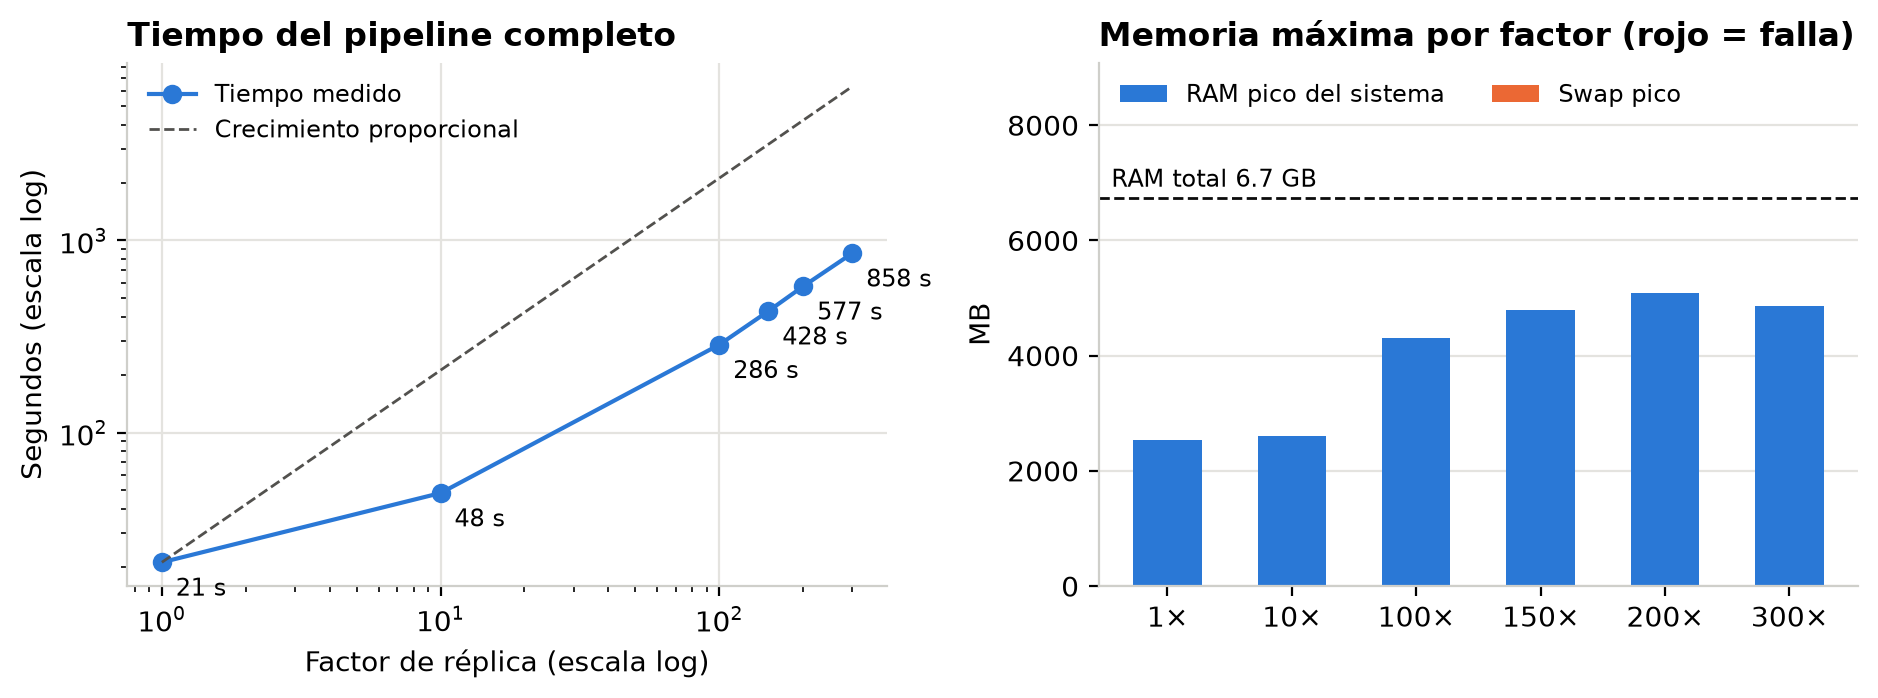

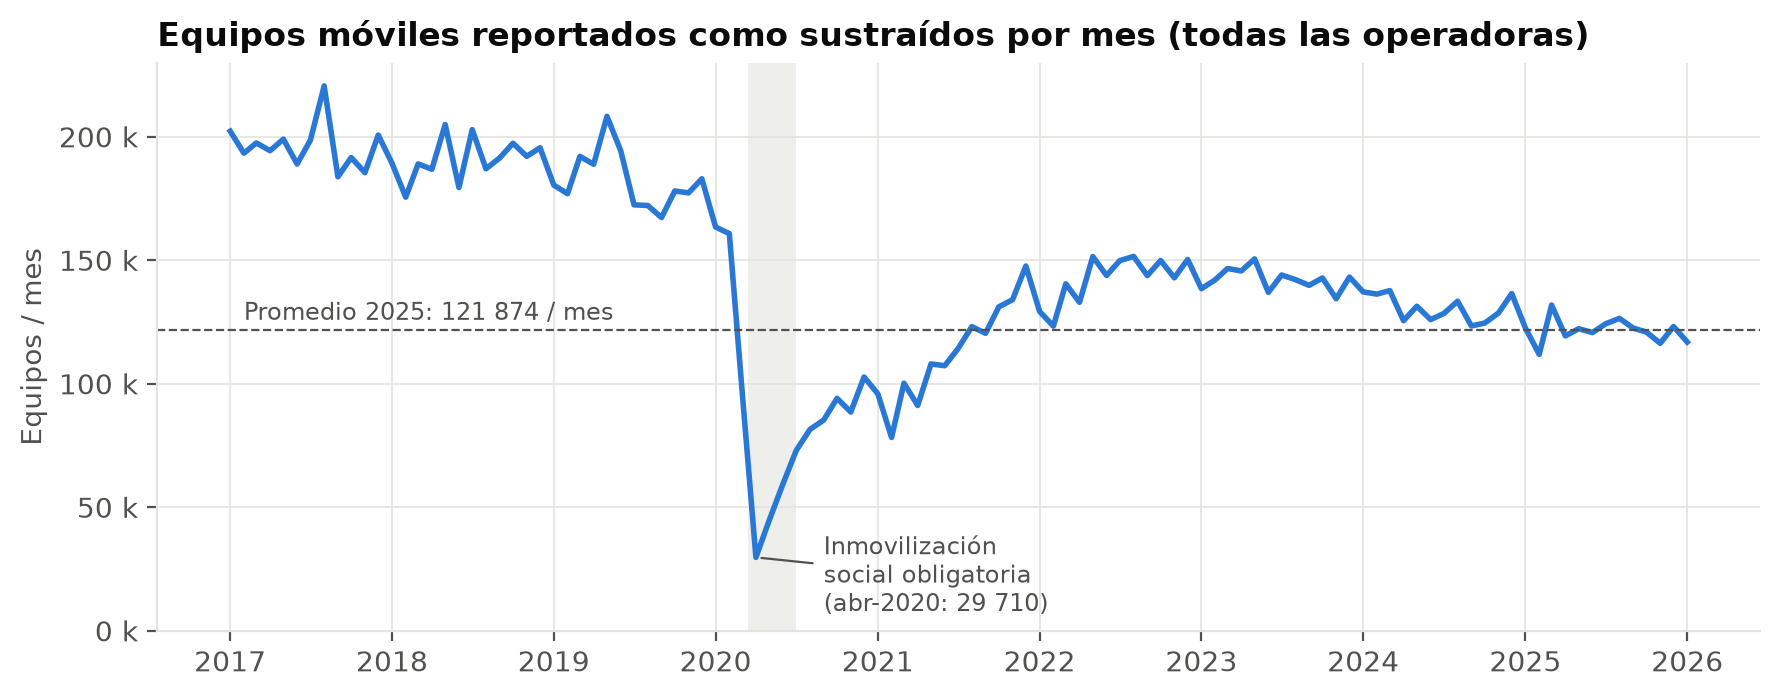

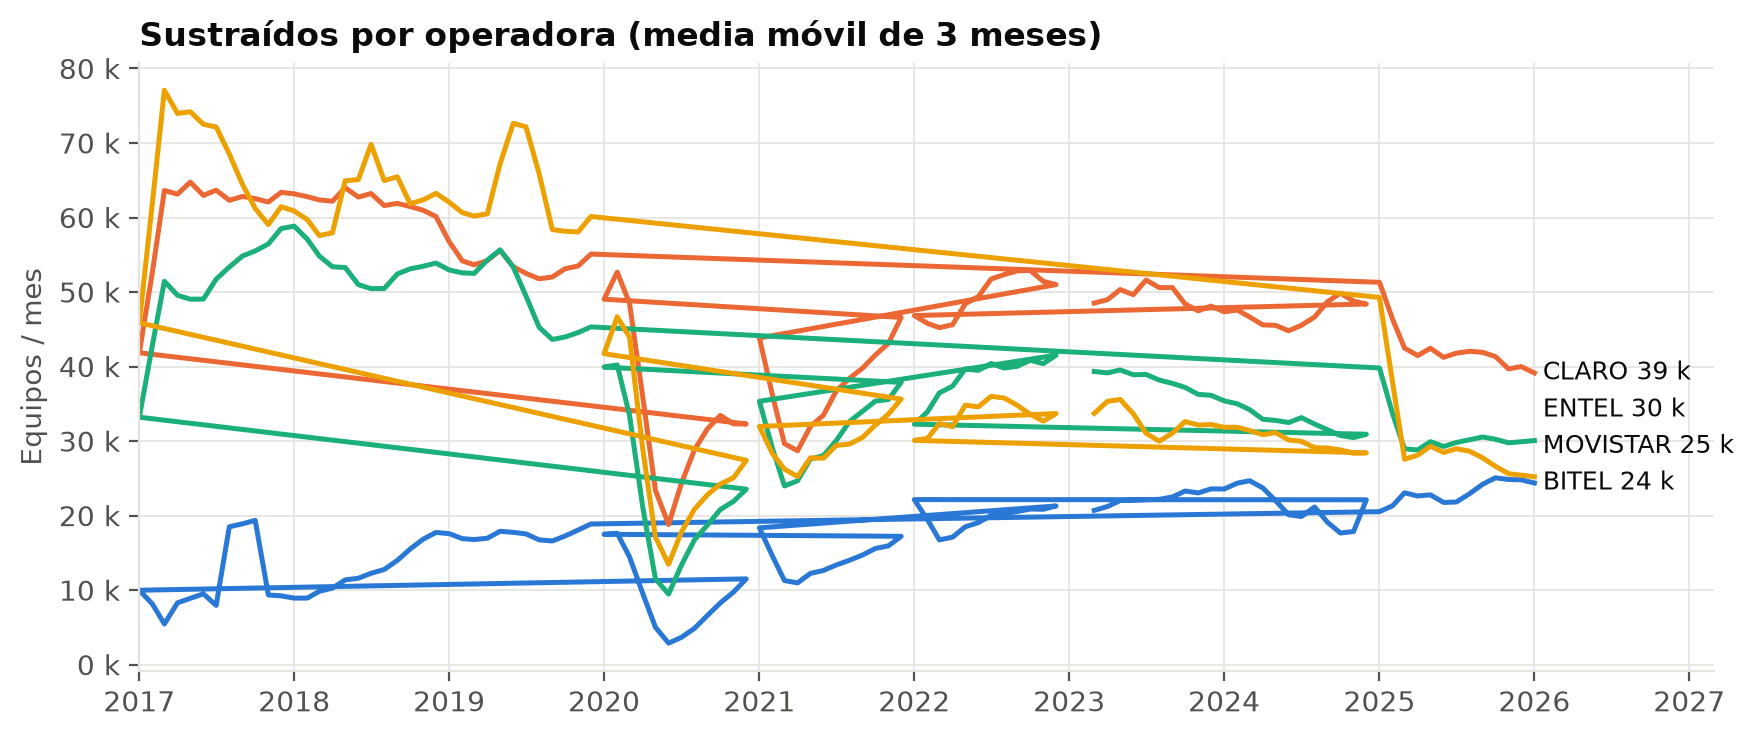

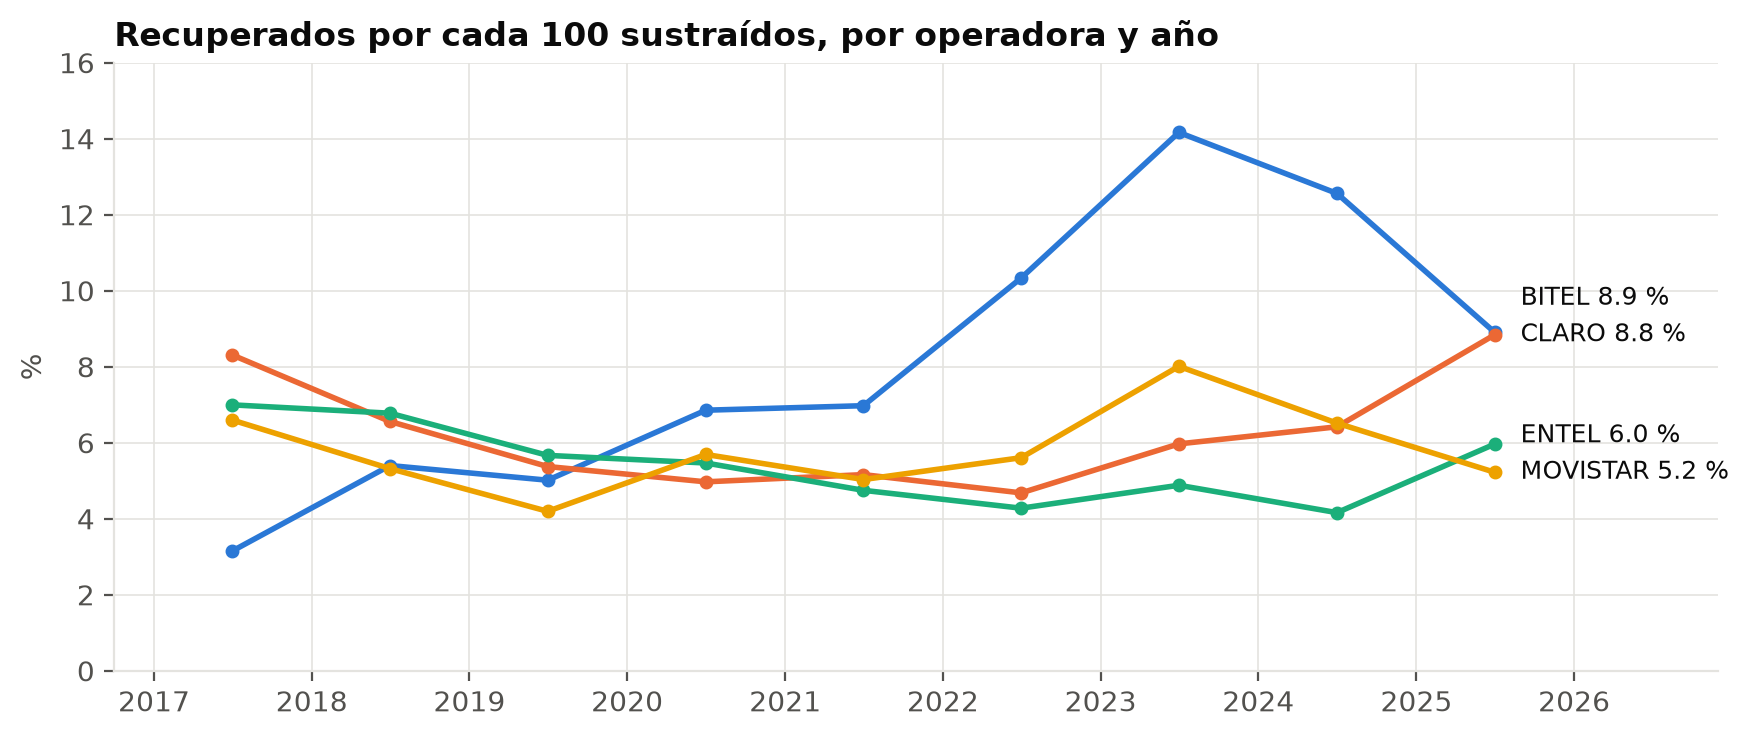

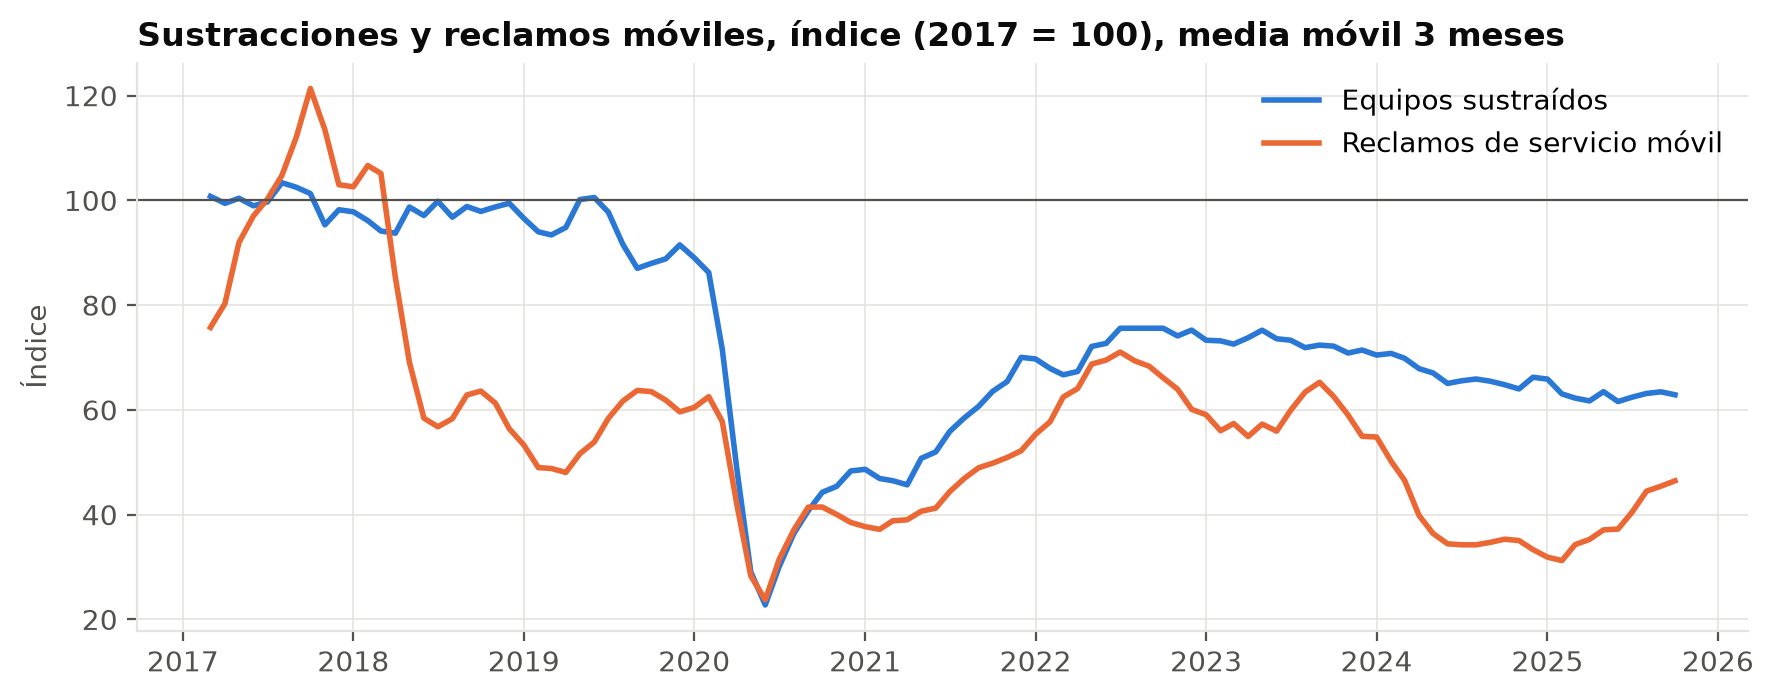

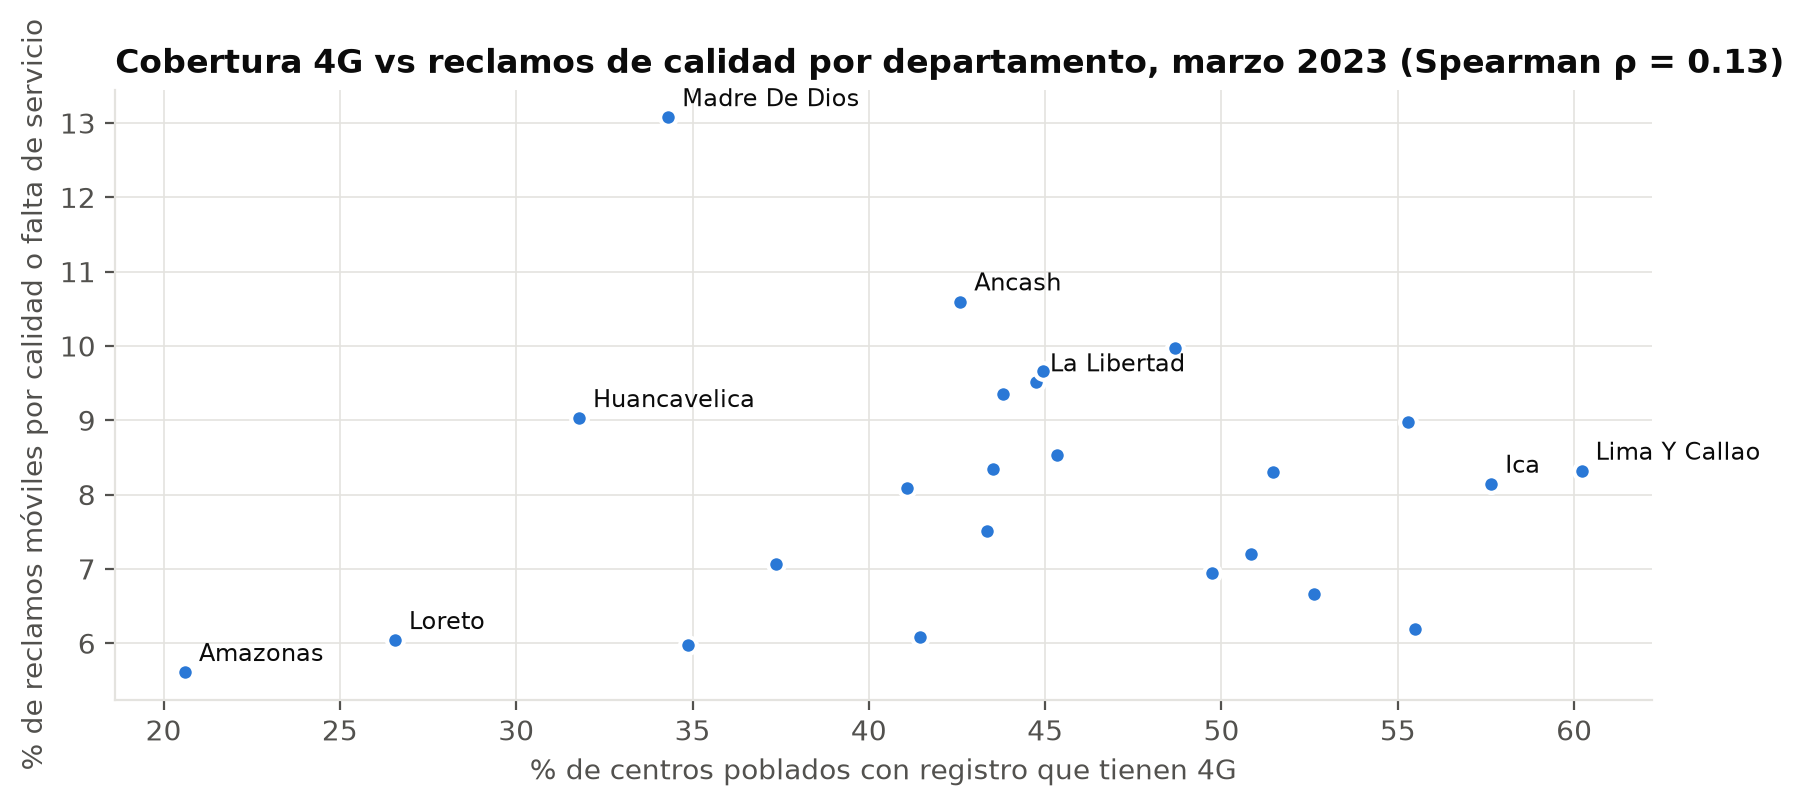

In [8]:
g = j1.toPandas(); j = j2.toPandas()
EVID = config.EVIDENCIA
modelo.ejecutar(g, EVID)   # modelo base + definitivo (sección 5)
figuras.main(g, j, EVID, RAIZ / 'docs' / 'figuras')
from IPython.display import Image, display
for f in sorted((RAIZ / 'docs' / 'figuras').glob('fig[1-5]*.png')):
    display(Image(filename=str(f), width=850))

## 5. Modelo: base (ingenuo) vs definitivo

H1 2018-02-01 a 2024-06-01 (sin 2020-03 a 2021-03) | prueba 2024-07-01 a 2026-01-01


,MAE,MAPE,MASE,sesgo
ingenuo,1956.8,7.03,0.809,118.8
ingenuo_estacional,2185.2,7.9,0.903,64.9
ridge,1831.8,6.63,0.757,412.2
random_forest,1737.3,6.32,0.718,143.9
gradient_boosting,1707.8,6.1,0.706,-66.1


H3 2018-04-01 a 2024-06-01 (sin 2020-03 a 2021-03) | prueba 2024-07-01 a 2026-01-01


,MAE,MAPE,MASE,sesgo
ingenuo,2377.6,8.28,0.733,345.4
ingenuo_estacional,3325.9,12.01,1.025,59.0
ridge,2642.9,9.29,0.815,1216.5
random_forest,2192.7,7.76,0.676,349.5
gradient_boosting,2182.2,7.67,0.673,534.2


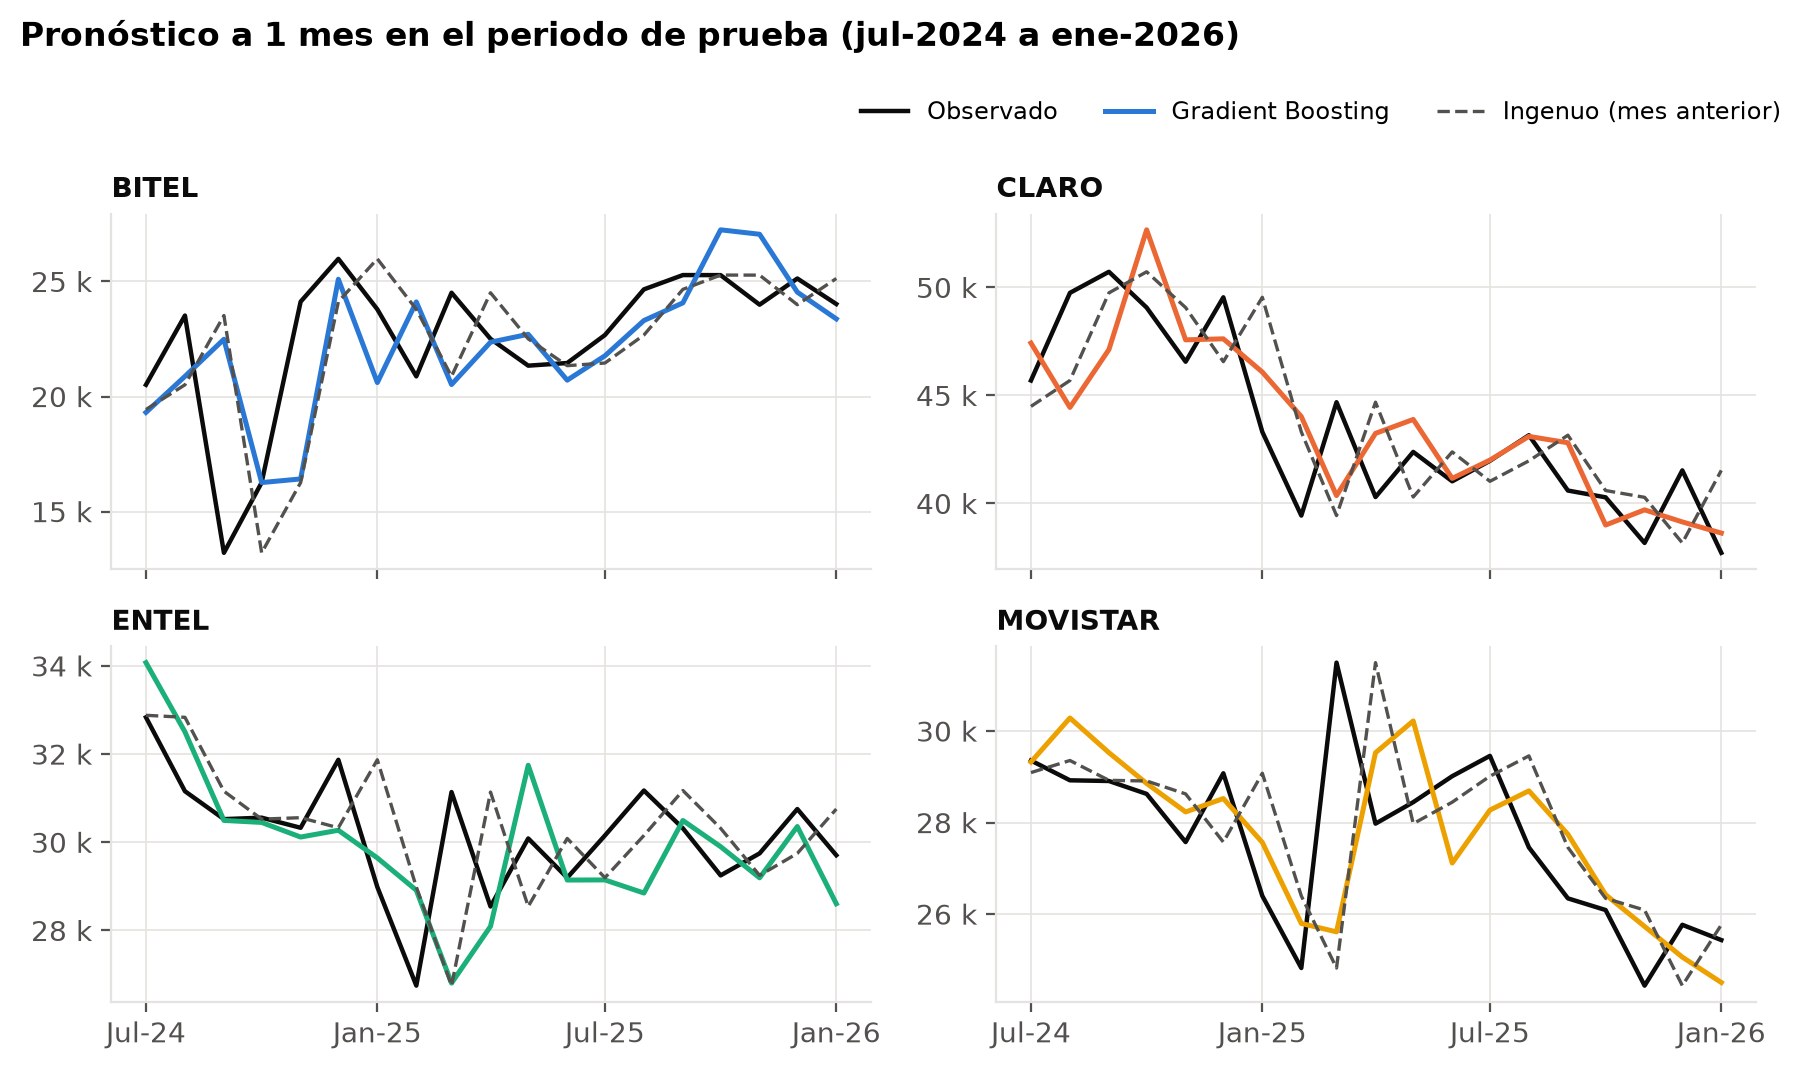

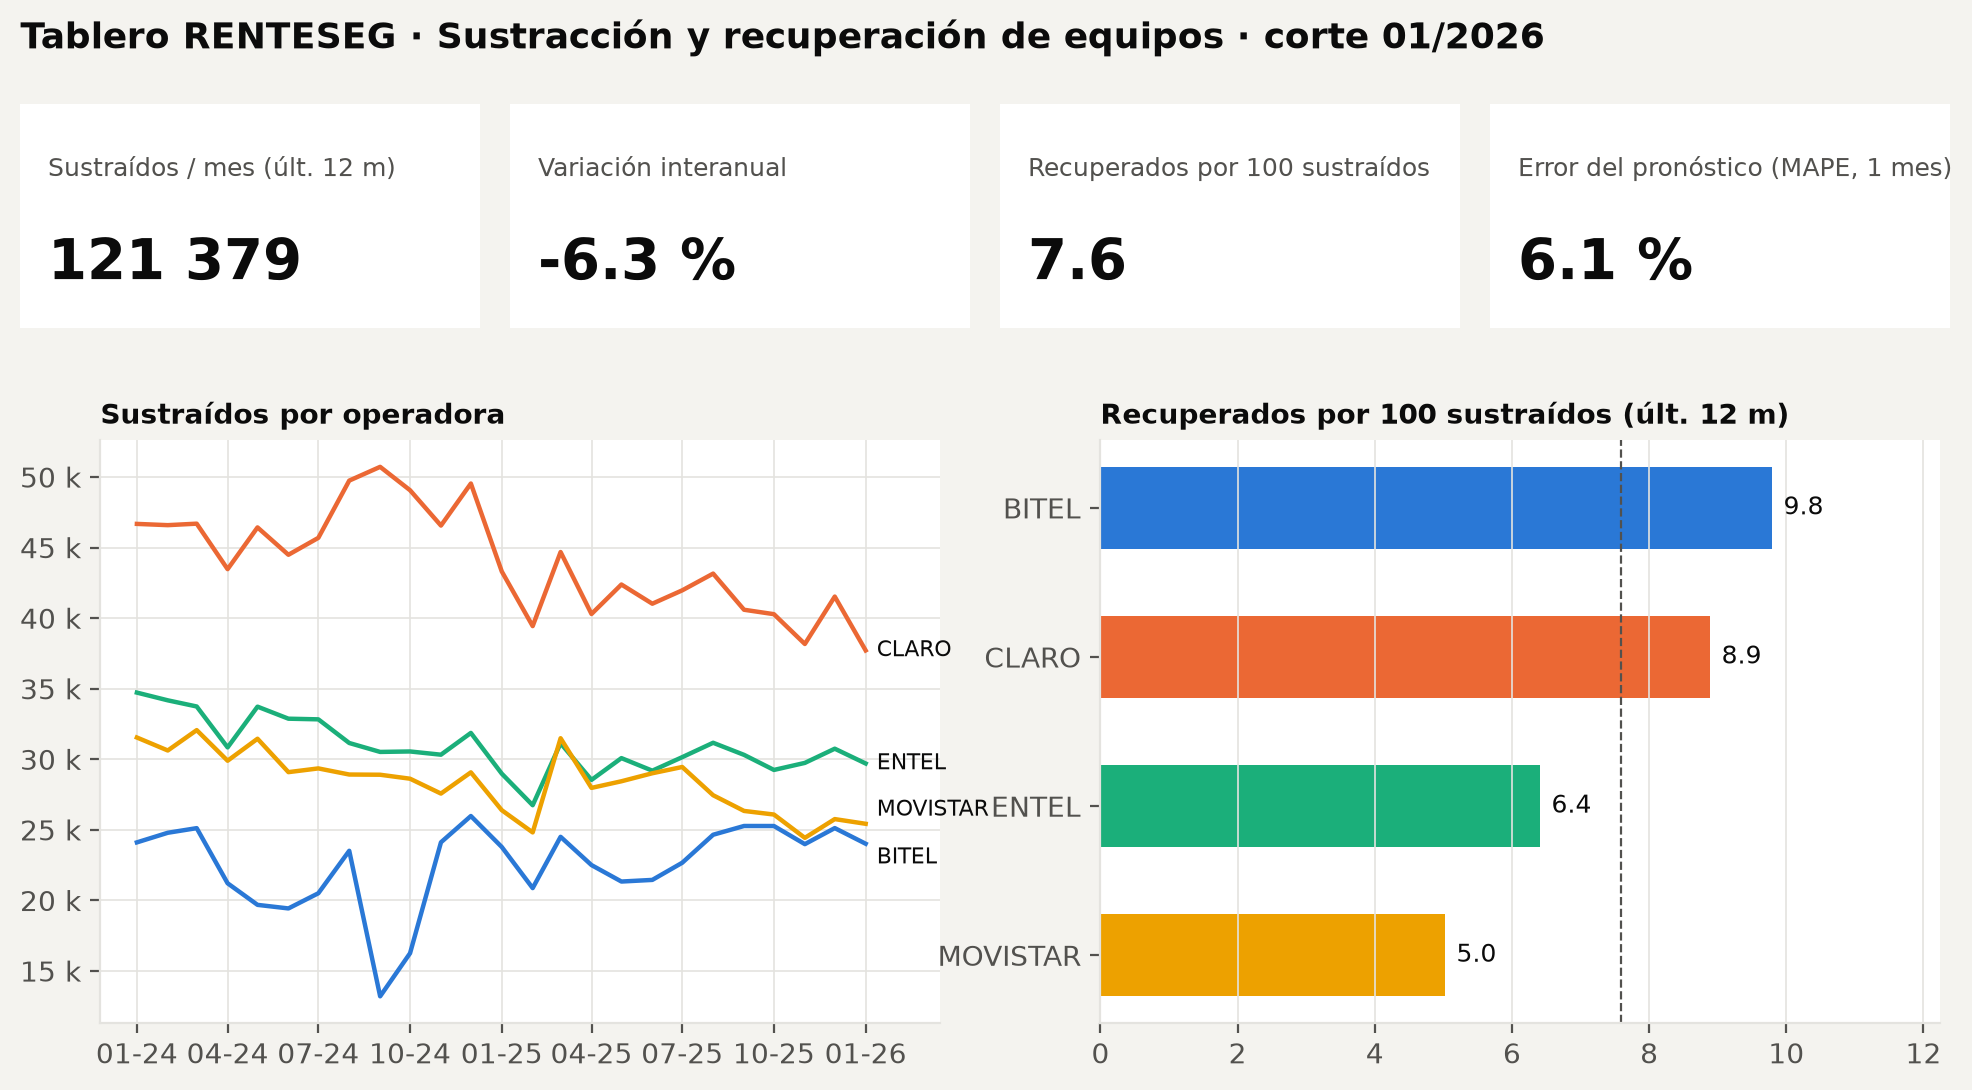

In [9]:
m = json.load(open(EVID / 'modelo_metricas.json', encoding='utf-8'))
for h in ('H1','H3'):
    print(h, m[h]['train'], '| prueba', m[h]['test'])
    display(pd.DataFrame(m[h]['metricas']).T.drop(columns='MAPE_por_operadora'))
display(Image(filename=str(RAIZ/'docs'/'figuras'/'fig6_modelo_prueba.png'), width=850))
display(Image(filename=str(RAIZ/'docs'/'figuras'/'fig7_tablero.png'), width=850))

## 5b. Tablero interactivo (capa de consumo)

Genera `docs/index.html`: se abre con doble clic o se publica con GitHub Pages (Settings → Pages → rama `main`, carpeta `/docs`).

In [10]:
import tablero
datos = tablero.generar(g, j, EVID, RAIZ / 'docs' / 'index.html', manifiesto['fuentes'])
pd.DataFrame(datos['operadoras'])[['op','estado','tasa12','potencial','pron','pron_mae']]

[TABLERO] /home/olazabal/big-data-sustraccion-equipos-moviles-peru/docs/index.html (corte 2026-01, pronóstico 2026-02)


,op,estado,tasa12,potencial,pron,pron_mae
0,BITEL,Sobre la mediana,9.80,0,22803,2321
1,CLARO,Sobre la mediana,8.89,0,36933,2202
2,ENTEL,Prioritaria,6.41,4425,27956,1056
3,MOVISTAR,Prioritaria,5.03,8579,24118,1252


## 6. Rendimiento y escalabilidad

Ejecutar desde la terminal (tarda más): `python src/benchmark.py --optimizacion`, luego `export SPARK_DRIVER_MEMORY=3g` y `python src/benchmark.py --escalabilidad` (sube de 1× a 300× y se detiene en el primer factor que la VM no pueda completar: **esa falla es el punto de quiebre que pide el informe**). Después `python src/graficar_benchmark.py`.

In [11]:
for f in ('optimizacion.json', 'escalabilidad.json'):
    p = EVID / f
    print(f, '\n', p.read_text() if p.exists() else 'PENDIENTE: ejecutar src/benchmark.py')

optimizacion.json 
 {
  "maquina": {
    "fecha": "2026-11-06T19:46:03",
    "maquina": "Debian",
    "so": "Linux-6.1.0-35-amd64-x86_64-with-glibc2.36",
    "python": "3.11.2",
    "cpu_logicas": 4,
    "ram_total_gb": 6.73,
    "swap_total_gb": 1.02,
    "disco_libre_gb": 9.7
  },
  "spark": "3.5.1",
  "repeticiones": 6,
  "nota": "AQE desactivado en todas las corridas; 1 corrida de calentamiento descartada",
  "A_antes_sin_cache_ni_broadcast": {
    "promedio_s": 3.585,
    "desv_estandar_s": 1.172,
    "mediana_s": 3.289,
    "corridas_s": [
      5.784,
      3.053,
      2.384,
      3.525,
      3.713,
      3.051
    ]
  },
  "A_despues_con_cache_y_broadcast": {
    "promedio_s": 2.635,
    "desv_estandar_s": 0.258,
    "mediana_s": 2.566,
    "corridas_s": [
      2.57,
      2.562,
      2.766,
      2.431,
      3.09,
      2.393
    ]
  },
  "B_antes_sin_particion": {
    "promedio_s": 0.328,
    "desv_estandar_s": 0.052,
    "mediana_s": 0.319,
    "corridas_s": [
      0.